# Open-vocabulary detection on a moving robot camera: a 3D object map

The previous notebooks scored detectors on single, independent photos. A robot sees a **video**
from a moving camera, has **depth**, and knows its **pose**. That changes both the use case and
what can be measured:

* The task becomes *"where in the room is the telephone?"*: detect the object, lift the box to
  3D with the depth image, and transform it into the world frame.
* A static object must land at **the same 3D position from every viewpoint**. This multi-view
  consistency is a label-free check of the detector. A detection that lands far from every
  other detection of its class is probably a false positive. An object whose 3D position
  projects into the current frame but is not detected is probably a miss.

**What this notebook does:** runs three open-vocabulary detectors on 144 frames of TUM RGB-D
`freiburg1_desk` (a handheld Kinect circling an office desk, with motion-capture poses). It
back-projects every detection to a 3D point in the world frame, clusters the points into an
**object map**, and measures per-object recall, spurious-detection rate and 3D spread.

**What you'll learn:** pixel to camera to world transforms, robust depth sampling inside a box,
clustering detections into object instances, and how per-frame detector errors show up in a
3D map.

**Prerequisites:** notebook 01 (detector APIs), pinhole camera model and SE(3) poses
(`cvlab.geometry`, projects 07/08), `make data-04_open_vocab_detection`. Runtime is about 2 minutes
on an RTX 5060 Laptop GPU (8 GB).

## Setup

In [1]:
# --- Setup: imports, device, paths, style ---
# ovd.py (project scripts) wraps the detectors; cvlab provides TUM loading and geometry helpers.
import os
import sys
import time

os.environ["YOLO_AUTOINSTALL"] = "false"  # never let Ultralytics pip-install at runtime
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.cluster.hierarchy import fcluster, linkage

from cvlab import device as cvdevice
from cvlab import io as cvio
from cvlab import viz
from cvlab.geometry import invert_T, transform_points
from cvlab.tum import load_sequence

PROJECT = "04_open_vocab_detection"
sys.path.insert(0, str(cvio.project_dir(PROJECT) / "scripts"))
import ovd  # noqa: E402

device = cvdevice.setup(seed=0)
viz.set_style()

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


## 1. Data: RGB, depth, intrinsics and poses

TUM RGB-D gives, for every frame, a 640x480 RGB image, a registered depth image
($d = \text{value}/5000$ metres, 0 = missing), the intrinsics $\mathbf{K}$ of the RGB camera,
and a motion-capture pose $\mathbf{T}_{wc} \in SE(3)$ (camera-to-world). Every 4th frame of the
573 is used, which gives 144 frames covering the whole sequence (about 20 s of handheld motion).

573 frames in the sequence, using 144; duration 19.8 s
K =
 [[517.3   0.  318.6]
 [  0.  516.5 255.3]
 [  0.    0.    1. ]]


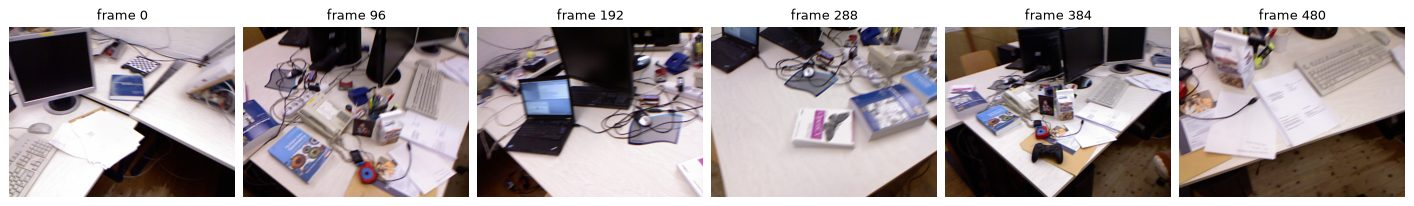

In [2]:
# --- Load the sequence and pick every 4th frame ---
seq = load_sequence(cvio.data_dir("tum", "fr1_desk", "rgbd_dataset_freiburg1_desk"))
FRAMES = list(range(0, len(seq), 4))
K = seq.camera.K  # 3x3 pinhole intrinsics (fx=517.3, fy=516.5, cx=318.6, cy=255.3)
print(f"{len(seq)} frames in the sequence, using {len(FRAMES)}; "
      f"duration {seq.timestamps[FRAMES[-1]] - seq.timestamps[0]:.1f} s")
print("K =\n", K.round(1))
VOCAB = ["telephone", "game controller", "laptop", "stapler", "cereal box", "computer mouse", "keyboard"]
fig = viz.show_images([seq.rgb(i) for i in FRAMES[::24]], [f"frame {i}" for i in FRAMES[::24]], ncols=6, size=2.6)
ovd.show_jpeg(fig)  # photo grid -> JPEG output to keep the notebook small

## 2. Lifting a detection to 3D

For a box with centre $(u, v)$, the depth is taken as the **median of the valid depth pixels in
the central 30 % of the box**. The median ignores missing depth (0), the background visible
around the object edges, and Kinect noise. Back-projection to the camera frame and
transformation to the world frame:

$$\mathbf{X}_c = d\,\mathbf{K}^{-1}\begin{bmatrix}u\\ v\\ 1\end{bmatrix}, \qquad
\mathbf{X}_w = \mathbf{R}_{wc}\,\mathbf{X}_c + \mathbf{t}_{wc}.$$

The reverse direction is used later to decide whether a mapped object should be visible in a
frame: project $\mathbf{X}_c = \mathbf{T}_{wc}^{-1}\mathbf{X}_w$ with $\mathbf{K}$, check that
it lands inside the image, and check that the measured depth there is not much smaller
(otherwise something is in front of it).

In [3]:
# --- Geometry helpers: box -> 3D world point, world point -> visibility in a frame ---
def box_depth(depth, box, frac=0.3):
    # median valid depth [m] in the central `frac` of the box (None if no valid pixel)
    x1, y1, x2, y2 = box
    cx, cy, hw, hh = (x1 + x2) / 2, (y1 + y2) / 2, frac * (x2 - x1) / 2, frac * (y2 - y1) / 2
    patch = depth[int(cy - hh):int(cy + hh) + 1, int(cx - hw):int(cx + hw) + 1]
    valid = patch[patch > 0]
    return float(np.median(valid)) if valid.size >= 5 else None


def box_to_world(box, depth, T_wc):
    d = box_depth(depth, box)
    if d is None:
        return None
    u, v = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
    X_c = d * np.linalg.solve(K, np.array([u, v, 1.0]))  # camera frame (x right, y down, z forward)
    return transform_points(T_wc, X_c[None])[0]  # world (motion-capture) frame


def is_visible(X_w, depth, T_wc, margin=20, occ_tol=0.10):
    # True if X_w projects inside the image and is not occluded (measured depth >= z - tol)
    X_c = transform_points(invert_T(T_wc), X_w[None])[0]
    if X_c[2] <= 0.1:
        return False
    u, v = (K @ X_c)[:2] / X_c[2]
    if not (margin <= u < 640 - margin and margin <= v < 480 - margin):
        return False
    d = depth[int(v), int(u)]
    return bool(d == 0 or d >= X_c[2] - occ_tol)


# sanity check: a pixel lifted to 3D and projected back lands on itself
T0, D0 = seq.gt_poses[0], seq.depth(0)
Xw = box_to_world((300, 200, 340, 240), D0, T0)
Xc = transform_points(invert_T(T0), Xw[None])[0]
print("round trip pixel:", ((K @ Xc)[:2] / Xc[2]).round(2), "(expected [320, 220])")

round trip pixel: [320. 220.] (expected [320, 220])


## 3. Detect, lift, accumulate

Each detector runs on all 144 frames with the same 7-word vocabulary and the per-model
thresholds used in notebook 01 (the F1-optimal score on the COCO subset, read from
`results/coco_<model>.json`). Every detection above threshold whose box has valid depth becomes
a 3D observation `(frame, class, score, X_w)`. The three models span the design space:
**YOLOE-26-s** (fast late fusion), **LLMDet-T** (early fusion, the strongest Grounding-DINO-style
model in notebook 02) and **SAM 3** (concept segmentation with a presence head).

In [4]:
# --- Run the detectors over the sequence and back-project every detection ---
RESULTS = cvio.project_dir(PROJECT) / "results"
MODELS = {k: cvio.load_json(RESULTS / f"coco_{k}.json")["f1_curve"]["best_threshold"]
          for k in ("yoloe26s", "llmdet_t", "sam3")}  # key -> score threshold
print("thresholds:", MODELS)
rgb = {i: seq.rgb(i) for i in FRAMES}
depth = {i: seq.depth(i) for i in FRAMES}  # metres, float32, 0 = missing
OBS, DETS, SPEED = [], {}, {}
for key, thr in MODELS.items():
    kw = {"dtype": "bfloat16"} if key == "sam3" else {}
    det = ovd.load_detector(key, **kw).set_vocabulary(VOCAB)
    det.predict(rgb[FRAMES[0]], min_score=thr)  # warm-up
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for i in FRAMES:
        d = det.predict(rgb[i], min_score=thr)
        DETS[(key, i)] = d
        for box, s, name in zip(d.boxes, d.scores, d.label_names):
            X = box_to_world(box, depth[i], seq.gt_poses[i])
            if X is not None:
                OBS.append({"model": key, "frame": i, "cls": name, "score": float(s),
                            "x": X[0], "y": X[1], "z": X[2]})
    torch.cuda.synchronize()
    SPEED[key] = 1000 * (time.perf_counter() - t0) / len(FRAMES)
    print(f"{det.label}: {SPEED[key]:.1f} ms/frame, {sum(len(DETS[(key, i)]) for i in FRAMES)} detections")
    ovd.free_detector(det)
obs = pd.DataFrame(OBS)
obs.groupby(["model", "cls"]).size().unstack(0).fillna(0).astype(int)

thresholds: {'yoloe26s': 0.3, 'llmdet_t': 0.35, 'sam3': 0.7}


YOLOE-26-s: 8.7 ms/frame, 364 detections


LLMDet-T: 181.6 ms/frame, 1072 detections


SAM 3: 520.6 ms/frame, 630 detections


model,llmdet_t,sam3,yoloe26s
cls,,,
cereal box,249,7,57
computer mouse,131,114,35
game controller,93,76,11
keyboard,174,213,100
laptop,145,59,109
stapler,118,10,7
telephone,70,79,6


## 4. From observations to an object map

The world points of one class are clustered with **average-linkage agglomerative clustering**,
cut at 0.15 m: two detections more than about 15 cm apart are treated as different objects
(e.g. two keyboards). A cluster supported by at least 5 frames becomes a **map object**, with
its position given by the median of its points. Observations in smaller clusters are counted as
**spurious**: they do not agree with any other viewpoint.

For each map object the evaluation goes back through every frame:
* **visible**: the object's map position projects into the frame and is not occluded;
* **detected**: a detection of that class in the frame lies within 0.15 m of the map position.

$\text{recall} = \#\text{detected} / \#\text{visible}$. The **spread** is the median distance of
the cluster's points to its centre, which measures how stable the 3D estimate is. Note that
this is geometric self-consistency, not human ground truth. A false positive that is repeated
consistently in the same place (e.g. a phone-shaped object always called "stapler") would still
form a map object.

In [5]:
# --- Cluster observations into map objects and score recall / spurious rate / spread ---
CLUSTER_M, MIN_SUPPORT, MATCH_M = 0.15, 5, 0.15
objects, rows = [], []
for (key, cls), g in obs.groupby(["model", "cls"]):
    P = g[["x", "y", "z"]].to_numpy()
    labels = fcluster(linkage(P, "average"), CLUSTER_M, "distance") if len(P) > 1 else np.ones(1, int)
    for lab in np.unique(labels):
        pts = P[labels == lab]
        n_frames = g[labels == lab].frame.nunique()
        if n_frames < MIN_SUPPORT:
            continue
        c = np.median(pts, 0)
        objects.append({"model": key, "cls": cls, "center": c, "support": n_frames,
                        "spread_cm": 100 * float(np.median(np.linalg.norm(pts - c, axis=1)))})
for o in objects:
    g = obs[(obs.model == o["model"]) & (obs.cls == o["cls"])]
    vis = det_ok = 0
    for i in FRAMES:
        if not is_visible(o["center"], depth[i], seq.gt_poses[i]):
            continue
        vis += 1
        gi = g[g.frame == i]
        if len(gi) and np.min(np.linalg.norm(gi[["x", "y", "z"]].to_numpy() - o["center"], axis=1)) < MATCH_M:
            det_ok += 1
    o["visible"], o["detected"] = vis, det_ok
# spurious = observations farther than MATCH_M from every map object of their class (same model)
spurious = {}
for key in MODELS:
    o_k = [o for o in objects if o["model"] == key]
    g = obs[obs.model == key]
    far = 0
    for _, r in g.iterrows():
        cs = [o["center"] for o in o_k if o["cls"] == r.cls]
        if not cs or np.min(np.linalg.norm(np.array(cs) - [r.x, r.y, r.z], axis=1)) >= MATCH_M:
            far += 1
    spurious[key] = (far, len(g))
obj_df = pd.DataFrame([{**{k: v for k, v in o.items() if k != "center"},
                        "recall": o["detected"] / max(o["visible"], 1)} for o in objects])
obj_df.sort_values(["model", "cls"]).round(3)

,model,cls,support,spread_cm,visible,detected,recall
0,llmdet_t,cereal box,37,3.905,63,32,0.508
1,llmdet_t,cereal box,35,4.467,57,33,0.579
2,llmdet_t,cereal box,69,1.858,66,62,0.939
3,llmdet_t,cereal box,5,4.083,91,4,0.044
4,llmdet_t,cereal box,8,2.438,50,8,0.160
...,...,...,...,...,...,...,...
62,yoloe26s,laptop,11,4.436,85,11,0.129
63,yoloe26s,laptop,12,6.552,74,14,0.189
64,yoloe26s,laptop,6,6.999,72,13,0.181
65,yoloe26s,laptop,10,4.168,68,12,0.176


## Results

**Qualitative frames.** Four frames from different viewpoints with the detections of each model.

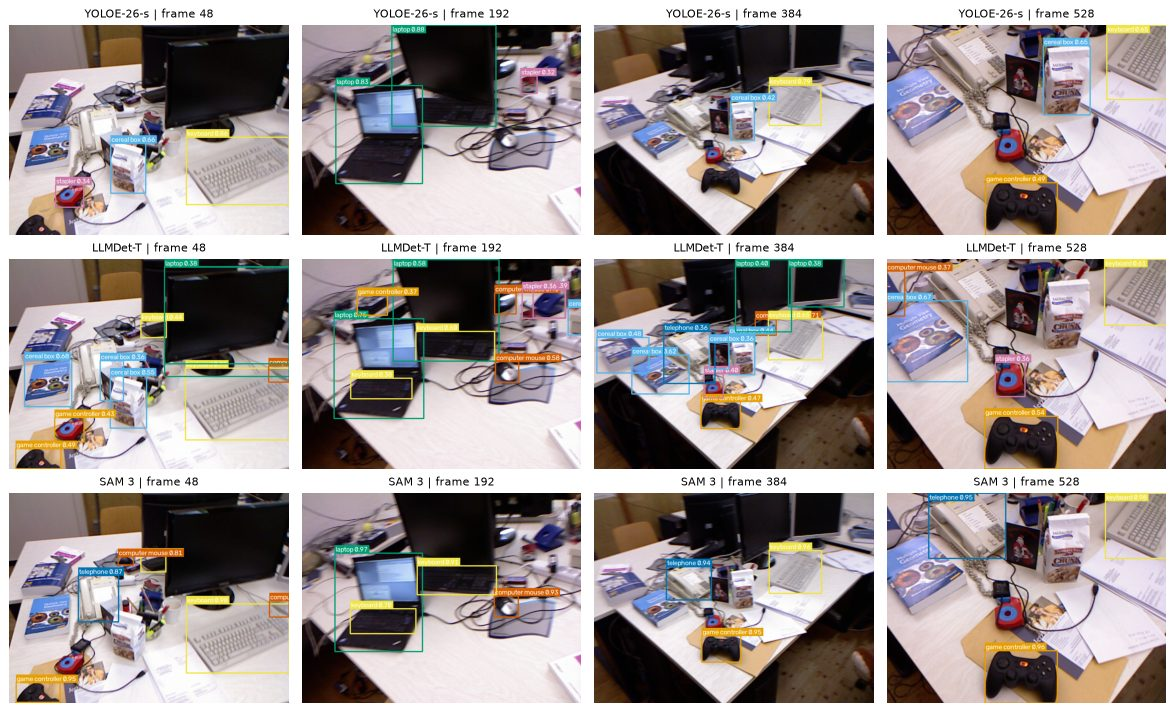

In [6]:
# --- Figure: detections on four frames (rows = models) ---
show = [FRAMES[12], FRAMES[48], FRAMES[96], FRAMES[132]]
fig, axes = plt.subplots(len(MODELS), len(show), figsize=(13, 2.6 * len(MODELS)))
for r, key in enumerate(MODELS):
    for c, i in enumerate(show):
        d = DETS[(key, i)]
        axes[r, c].imshow(viz.draw_boxes(rgb[i], d.boxes, d.label_names, d.scores,
                                         [VOCAB.index(n) for n in d.label_names]))
        axes[r, c].set_title(f"{ovd.MODEL_INFO[key][0]} | frame {i}", fontsize=9)
        axes[r, c].axis("off")
viz.savefig(fig, PROJECT, "object_map_frames")
ovd.show_jpeg(fig)

**Top-down object map.** World-frame x-y positions of every observation (small dots), the map
objects (large markers) and the camera trajectory, one panel per model. Tight clusters show
consistent detections. Scattered dots are spurious detections or poor depth.

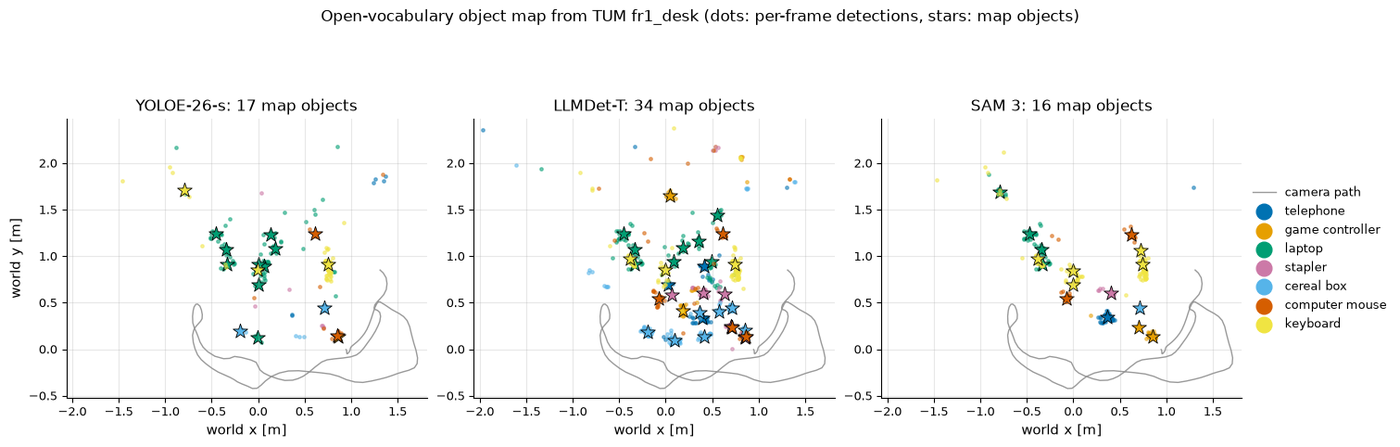

In [7]:
# --- Figure: top-down 3D object map per model ---
cam = seq.gt_poses[FRAMES][:, :3, 3]  # camera centres in the world frame [m]
fig, axes = plt.subplots(1, len(MODELS), figsize=(15, 5.2))
# common limits for all panels (equal aspect + shared axes is not allowed in matplotlib)
P_all = np.vstack([obs[["x", "y"]].to_numpy(), cam[:, :2]])
lo, hi = P_all.min(0) - 0.1, P_all.max(0) + 0.1
for ax, key in zip(axes, MODELS):
    ax.plot(cam[:, 0], cam[:, 1], "-", color="0.6", lw=1, label="camera path")
    g = obs[obs.model == key]
    for j, cls in enumerate(VOCAB):
        gc = g[g.cls == cls]
        col = viz.color(j, unit=True)
        ax.scatter(gc.x, gc.y, s=6, color=col, alpha=0.5)
        for o in objects:
            if o["model"] == key and o["cls"] == cls:
                ax.scatter(*o["center"][:2], s=140, marker="*", color=col, edgecolor="k", lw=0.6)
        ax.scatter([], [], color=col, label=cls)  # legend proxy
    ax.set_title(f"{ovd.MODEL_INFO[key][0]}: {sum(o['model'] == key for o in objects)} map objects")
    ax.set_xlabel("world x [m]")
    ax.set_xlim(lo[0], hi[0])
    ax.set_ylim(lo[1], hi[1])
    ax.set_aspect("equal", adjustable="box")
axes[0].set_ylabel("world y [m]")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5), markerscale=2)
fig.suptitle("Open-vocabulary object map from TUM fr1_desk (dots: per-frame detections, stars: map objects)")
viz.savefig(fig, PROJECT, "object_map")
plt.show()

**Per-class recall and 3D spread.** For each model and class the map object with the most
support is shown (some classes, like keyboards, have several instances).

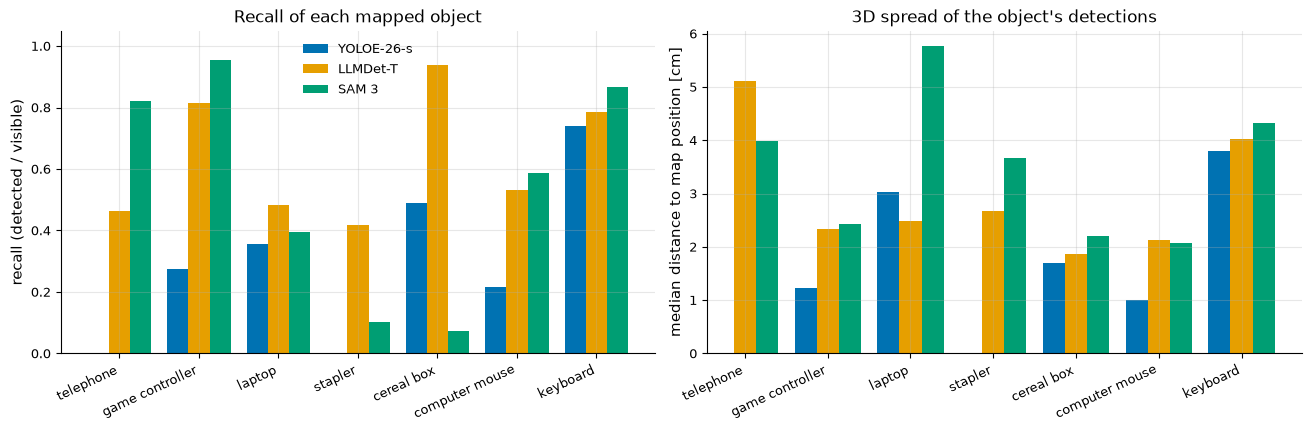

In [8]:
# --- Figure: recall and spread of the best-supported map object per class ---
best = obj_df.sort_values("support", ascending=False).groupby(["model", "cls"]).head(1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
w = 0.8 / len(MODELS)
for m, key in enumerate(MODELS):
    b = best[best.model == key].set_index("cls").reindex(VOCAB)
    x = np.arange(len(VOCAB)) + (m - (len(MODELS) - 1) / 2) * w
    axes[0].bar(x, b.recall.fillna(0), w, label=ovd.MODEL_INFO[key][0], color=viz.color(m, unit=True))
    axes[1].bar(x, b.spread_cm, w, label=ovd.MODEL_INFO[key][0], color=viz.color(m, unit=True))
for ax, yl, t in [(axes[0], "recall (detected / visible)", "Recall of each mapped object"),
                  (axes[1], "median distance to map position [cm]", "3D spread of the object's detections")]:
    ax.set_xticks(range(len(VOCAB)), VOCAB, rotation=25, ha="right")
    ax.set_ylabel(yl)
    ax.set_title(t)
axes[0].set_ylim(0, 1.05)
axes[0].legend()
viz.savefig(fig, PROJECT, "object_map_recall")
plt.show()

**Summary table** (per model; recall averaged over the best-supported object of each class that
was mapped; spurious = observations that agree with no map object).

In [9]:
# --- Summary table per model ---
summary = pd.DataFrame([{
    "model": ovd.MODEL_INFO[key][0],
    "threshold": thr,
    "ms / frame": round(SPEED[key], 1),
    "detections (with depth)": spurious[key][1],
    "map objects": int((obj_df.model == key).sum()),
    "classes mapped (of 7)": int(best[best.model == key].cls.nunique()),
    "mean recall": round(best[best.model == key].recall.mean(), 3),
    "median spread [cm]": round(best[best.model == key].spread_cm.median(), 1),
    "spurious [%]": round(100 * spurious[key][0] / max(spurious[key][1], 1), 1),
} for key, thr in MODELS.items()])
cvio.save_json(summary.to_dict("records"), cvio.project_dir(PROJECT) / "results" / "object_map_summary.json")
summary

,model,threshold,ms / frame,detections (with depth),map objects,classes mapped (of 7),mean recall,median spread [cm],spurious [%]
0,YOLOE-26-s,0.30,8.7,325,17,5,0.415,1.7,14.8
1,LLMDet-T,0.35,181.6,980,34,7,0.634,2.5,10.5
2,SAM 3,0.70,520.6,558,16,7,0.543,3.7,3.9


### Takeaways

144 frames of TUM fr1_desk, three detectors at their F1-optimal COCO thresholds, single run.
These metrics measure geometric self-consistency, not agreement with human labels.

* **Multi-view consistency is a cheap, label-free check.** The share of observations that agree
  with no map object is 3.9 % for SAM 3, 10.5 % for LLMDet-T and 14.8 % for YOLOE-26-s.
* **Consistent mistakes survive the map.** LLMDet-T has the highest mean recall (0.634) and maps
  all 7 classes, but builds 34 map objects for 7 prompts. In the frames above it also labels the
  blue books as *cereal box* (and the monitors as *laptop*), and because it does so from every viewpoint these boxes form stable
  map objects. Multi-view voting removes random errors, not systematic ones.
* **SAM 3 is the most precise and misses some objects.** 16 map objects, 3.9 % spurious, mean
  recall 0.543, and only 7 *cereal box* and 10 *stapler* observations in 144 frames. YOLOE-26-s is
  the fastest (8.7 ms per frame) but maps only 5 of the 7 classes (mean recall 0.415; 6
  *telephone* observations in 144 frames).
* **Box centre plus median depth gives centimetre-level repeatability.** The median spread of the
  best-supported objects is 1.7 cm (YOLOE-26-s), 2.5 cm (LLMDet-T) and 3.7 cm (SAM 3). The point
  lies on the visible surface, not at the object's centre. Exercise 2 fits an oriented 3D box
  from a SAM 3 mask instead.
* **Latency sets how the detector is used.** At 181.6 ms (LLMDet-T) and 520.6 ms (SAM 3) per frame,
  the heavy models run on keyframes at a few Hz, as a mapping system would anyway. YOLOE-26-s can
  run on every frame.

## Exercises

Solutions: `projects/04_open_vocab_detection/solutions/`.

**Exercise 1: temporal voting.** A robot can wait a few frames before trusting a detection.
Keep a detection only if the same class was also detected within 0.15 m (in the world frame) in
at least 2 of the previous 4 processed frames. Recompute the spurious rate and the recall. What
does the filter trade away?

In [10]:
# --- Exercise 1 (TODO): temporal voting filter ---
def voted(obs_model, window=4, min_votes=2, radius=0.15):
    # TODO: return the subset of rows of obs_model that are confirmed by earlier frames
    raise NotImplementedError

**Exercise 2: an oriented 3D box instead of a point.** Run SAM 3 with `masks=True` on one frame,
back-project the depth pixels inside the mask of the telephone with
`cvlab.pointcloud.depth_to_points`, remove outliers, and fit an oriented bounding box with
`cvlab.pointcloud.pca_obb`. How do its extents compare with a real desk phone (about
20 x 20 x 10 cm)?

In [11]:
# --- Exercise 2 (TODO): mask -> point cloud -> oriented 3D box ---
from cvlab.pointcloud import depth_to_points, pca_obb, remove_statistical_outliers  # noqa: F401

frame = FRAMES[100]
# TODO: det = ovd.load_detector("sam3", dtype="bfloat16").set_vocabulary(["telephone"])
#       d = det.predict(rgb[frame], min_score=0.5, masks=True); use d.masks[0] and depth[frame]